In [13]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from tinkoff.invest.sandbox.client import SandboxClient as Client
from tinkoff.invest import SecurityTradingStatus
from tinkoff.invest.services import InstrumentsService
from tinkoff.invest.utils import quotation_to_decimal

TOKEN = 't.DBEaAVcPDDWGkElTk898UNX9yH_ADegVdZgaWKC4a-Ktgz1sbbd-G_9yQf0PeiVEeKuoMWEpUuMT-TNCQzaw1g'


def extract_tickers(url):
    # Send a GET request to the webpage
    response = requests.get(url)
    response.raise_for_status()  # Check for request errors

    # Parse the HTML content
    soup = BeautifulSoup(response.text, 'html.parser')

    # Find all rows matching the pattern
    rows = soup.find_all('tr', class_="row-RdUXZpkv listRow")

    # Extract tickers from the 'data-rowkey' attribute
    tickers = [row['data-rowkey'].split(':')[1] for row in rows if 'data-rowkey' in row.attrs]

    return tickers

def get_figis(input_tickers):
    """Gets list of ticker-figi indexes pairs for given list of tickers"""
    result = []
    
    with Client(TOKEN) as client:
        instruments: InstrumentsService = client.instruments
        tickers = []
        for method in ["shares", "bonds", "etfs", "currencies", "futures"]:
            for item in getattr(instruments, method)().instruments:
                tickers.append(
                    {
                        "name": item.name,
                        "ticker": item.ticker,
                        "class_code": item.class_code,
                        "figi": item.figi,
                        "uid": item.uid,
                        "type": method,
                        "min_price_increment": quotation_to_decimal(
                            item.min_price_increment
                        ),
                        "scale": 9 - len(str(item.min_price_increment.nano)) + 1,
                        "lot": item.lot,
                        "trading_status": str(
                            SecurityTradingStatus(item.trading_status).name
                        ),
                        "api_trade_available_flag": item.api_trade_available_flag,
                        "currency": item.currency,
                        "exchange": item.exchange,
                        "buy_available_flag": item.buy_available_flag,
                        "sell_available_flag": item.sell_available_flag,
                        "short_enabled_flag": item.short_enabled_flag,
                        "klong": quotation_to_decimal(item.klong),
                        "kshort": quotation_to_decimal(item.kshort),
                    }
                )

        tickers_df = pd.DataFrame(tickers)

        for ticker in input_tickers :
            ticker_df = tickers_df[tickers_df["ticker"] == ticker]
            
            if ticker_df.empty:
                logger.error("There is no such ticker: %s", ticker)
                return
    
            figi = ticker_df["figi"].iloc[0]
            
            result.append((ticker, figi))
    return result

if __name__ == "__main__":
    url = "https://www.tradingview.com/symbols/RUS-RTSI/components/"  # Replace with the actual URL
    tickers = extract_tickers(url)
    ticker_figis = get_figis(tickers)


In [14]:
ticker_figis

[('SBER', 'BBG004730N88'),
 ('SBERP', 'BBG0047315Y7'),
 ('ROSN', 'BBG004731354'),
 ('LKOH', 'BBG004731032'),
 ('GAZP', 'BBG004730RP0'),
 ('NVTK', 'BBG00475KKY8'),
 ('PLZL', 'BBG000R607Y3'),
 ('GMKN', 'BBG004731489'),
 ('TATNP', 'BBG004S68829'),
 ('TATN', 'BBG004RVFFC0'),
 ('SNGS', 'BBG0047315D0'),
 ('SNGSP', 'BBG004S681M2'),
 ('CHMF', 'BBG00475K6C3'),
 ('PHOR', 'BBG004S689R0'),
 ('NLMK', 'BBG004S681B4'),
 ('RUAL', 'BBG008F2T3T2'),
 ('MGNT', 'BBG004RVFCY3'),
 ('MOEX', 'BBG004730JJ5'),
 ('IRAO', 'BBG004S68473'),
 ('VTBR', 'BBG004730ZJ9'),
 ('MAGN', 'BBG004S68507'),
 ('ALRS', 'BBG004S68B31'),
 ('MTSS', 'BBG004S681W1'),
 ('CBOM', 'BBG009GSYN76'),
 ('PIKK', 'BBG004S68BH6'),
 ('HYDR', 'BBG00475K2X9'),
 ('AFLT', 'BBG004S683W7'),
 ('FLOT', 'BBG000R04X57'),
 ('ENPG', 'BBG000RMWQD4'),
 ('RTKM', 'BBG004S682Z6'),
 ('TRNFP', 'BBG00475KHX6'),
 ('BSPB', 'BBG000QJW156'),
 ('FEES', 'BBG00475JZZ6'),
 ('POSI', 'TCS00A103X66'),
 ('AFKS', 'BBG004S68614'),
 ('UPRO', 'BBG004S686W0'),
 ('MSNG', 'BBG004S687W8'

In [16]:
from tinkoff.invest import CandleInterval

def fetch_ohlcv_data(ticker_figis, start_date, end_date, interval):
    # List to store rows of data
    data_rows = []

    with Client(TOKEN) as client:
        for ticker, figi in ticker_figis:  # figis is now a list of (ticker, figi) tuples
            try:
                # Fetch candles for the FIGI
                candles = client.market_data.get_candles(
                    figi=figi,
                    from_=start_date,
                    to=end_date,
                    interval=interval,
                )
                # Append each candle as a row with ticker and figi
                for candle in candles.candles:
                    row = {
                        "figi": figi,
                        "date": candle.time,
                        "open": candle.open.units + candle.open.nano / 1e9,
                        "high": candle.high.units + candle.high.nano / 1e9,
                        "low": candle.low.units + candle.low.nano / 1e9,
                        "close": candle.close.units + candle.close.nano / 1e9,
                        "volume": candle.volume,
                        "tic": ticker,
                        "day": candle.time.weekday()
                    }
                    data_rows.append(row)
            except Exception as e:
                print(f"Failed to fetch data for FIGI {figi} (Ticker: {ticker}): {e}")

    # Convert the list of rows into a DataFrame
    df = pd.DataFrame(data_rows)
    return df

if __name__ == "__main__":
    # Set date range for historical data
    end_date = pd.Timestamp("2024-12-12T12:00:00Z")
    start_date = end_date - pd.Timedelta(days=10)  # Past 30 days
    interval = CandleInterval.CANDLE_INTERVAL_15_MIN   # Daily candles # CANDLE_INTERVAL_15_MIN
    data_df = fetch_ohlcv_data(ticker_figis, start_date, end_date, interval)

In [17]:
data_df

,figi,date,open,high,low,close,volume,tic,day
0,BBG004730N88,2024-12-02 12:00:00+00:00,236.23,236.83,236.23,236.70,73960,SBER,0
1,BBG004730N88,2024-12-02 12:15:00+00:00,236.67,237.34,236.10,236.20,146749,SBER,0
2,BBG004730N88,2024-12-02 12:30:00+00:00,236.20,236.38,236.00,236.10,47045,SBER,0
3,BBG004730N88,2024-12-02 12:45:00+00:00,236.06,236.23,235.27,235.28,89141,SBER,0
4,BBG004730N88,2024-12-02 13:00:00+00:00,235.31,235.82,235.19,235.61,71853,SBER,0
...,...,...,...,...,...,...,...,...,...
31496,RU000A106T36,2024-12-12 10:45:00+00:00,427.75,427.75,426.20,427.20,7184,ASTR,3
31497,RU000A106T36,2024-12-12 11:00:00+00:00,427.10,428.00,426.85,427.80,60720,ASTR,3
31498,RU000A106T36,2024-12-12 11:15:00+00:00,427.85,428.00,425.45,426.05,6557,ASTR,3
31499,RU000A106T36,2024-12-12 11:30:00+00:00,426.05,427.80,425.75,426.75,6931,ASTR,3


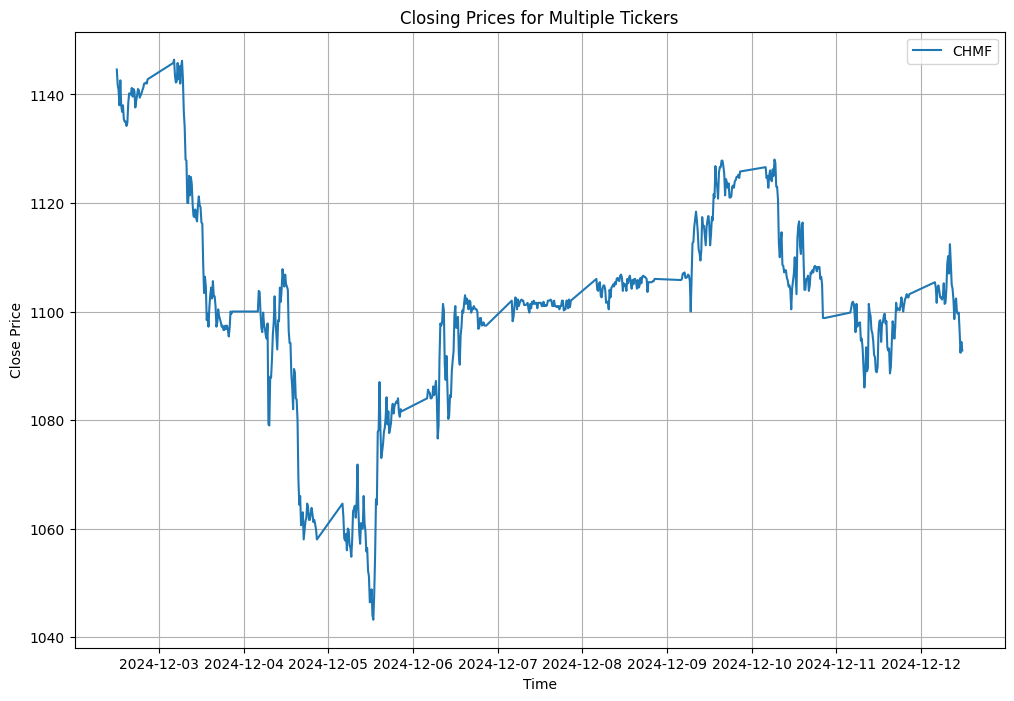

In [18]:
import matplotlib.pyplot as plt

def plot_multi_ticker_close(df, tickers):
    plt.figure(figsize=(12, 8))
    for ticker in tickers:
        ticker_data = df[df['tic'] == ticker]
        plt.plot(ticker_data['date'], ticker_data['close'], label=ticker)

    plt.title('Closing Prices for Multiple Tickers')
    plt.xlabel('Time')
    plt.ylabel('Close Price')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
plot_multi_ticker_close(data_df, ['CHMF'])


In [3]:
import requests
import pandas as pd
import logging
import time

from datetime import timedelta
from bs4 import BeautifulSoup
from tinkoff.invest.sandbox.client import SandboxClient as Client
from tinkoff.invest import SecurityTradingStatus
from tinkoff.invest.services import InstrumentsService
from tinkoff.invest.utils import quotation_to_decimal

def extract_tickers(url="https://www.tradingview.com/symbols/RUS-RTSI/components/"):
    retries = 3  # Number of retries
    backoff_factor = 2  # Exponential backoff factor (seconds)

    for attempt in range(retries):
        try:
            # Send a GET request to the webpage
            response = requests.get(url, timeout=10)
            response.raise_for_status()  # Check for request errors

            # Parse the HTML content
            soup = BeautifulSoup(response.text, 'html.parser')

            # Find all rows matching the pattern
            rows = soup.find_all('tr', class_="row-RdUXZpkv listRow")

            # Extract tickers from the 'data-rowkey' attribute
            tickers = [row['data-rowkey'].split(':')[1] for row in rows if 'data-rowkey' in row.attrs]

            return tickers

        except requests.exceptions.RequestException as e:
            print(f"Attempt {attempt + 1} failed: {e}")
            if attempt < retries - 1:  # Retry if there are attempts left
                sleep_time = backoff_factor * (2 ** attempt)
                print(f"Retrying in {sleep_time} seconds...")
                time.sleep(sleep_time)
            else:
                print("All retries failed. Exiting.")
                raise

tickers = extract_tickers()

In [4]:
tickers

['ROSN',
 'SBERP',
 'SBER',
 'LKOH',
 'GAZP',
 'NVTK',
 'PLZL',
 'GMKN',
 'TATN',
 'TATNP',
 'SNGSP',
 'SNGS',
 'CHMF',
 'NLMK',
 'PHOR',
 'RUAL',
 'MGNT',
 'MOEX',
 'MAGN',
 'VTBR',
 'MTSS',
 'ALRS',
 'IRAO',
 'CBOM',
 'PIKK',
 'AFLT',
 'HYDR',
 'RTKM',
 'ENPG',
 'FLOT',
 'TRNFP',
 'BSPB',
 'FEES',
 'AFKS',
 'POSI',
 'UPRO',
 'MSNG',
 'VKCO',
 'SMLT',
 'MTLR',
 'MTLRP',
 'SELG',
 'LEAS',
 'YDEX',
 'T',
 'ASTR',
 'SVCB',
 'UGLD',
 'HEAD']

In [42]:

import time
from datetime import timedelta
import pandas as pd

from tdata import get_figis, extract_tickers

def fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN):
    # List to store rows of data
    data_rows = []

    # Define the maximum period per request for each interval
    max_periods = {
        "CANDLE_INTERVAL_1_MIN": timedelta(days=1),  # Max 1 day for 1-minute candles
        "CANDLE_INTERVAL_5_MIN": timedelta(days=7),  # Max 7 days for 5-minute candles
        "CANDLE_INTERVAL_15_MIN": timedelta(days=14),  # Max 14 days for 15-minute candles
        "CANDLE_INTERVAL_HOUR": timedelta(days=30),  # Max 30 days for hourly candles
        "CANDLE_INTERVAL_DAY": timedelta(days=365),  # Max 1 year for daily candles
    }

    # Get the maximum allowable period for the given interval
    max_duration = max_periods.get(interval, timedelta(days=1))  # Default to 1 day if interval is unknown

    with Client(TOKEN) as client:
        for ticker, figi in ticker_figis:  # ticker_figis is a list of (ticker, figi) tuples
            current_start = start_date
            while current_start < end_date:
                # Calculate the end of the current chunk
                current_end = min(current_start + max_duration, end_date)
                try:
                    # Fetch candles for the current chunk
                    candles = client.market_data.get_candles(
                        figi=figi,
                        from_=current_start,
                        to=current_end,
                        interval=interval,
                    )
                    # Append each candle as a row with ticker and figi
                    for candle in candles.candles:
                        row = {
                            "figi": figi,
                            "date": candle.time,
                            "open": candle.open.units + candle.open.nano / 1e9,
                            "high": candle.high.units + candle.high.nano / 1e9,
                            "low": candle.low.units + candle.low.nano / 1e9,
                            "close": candle.close.units + candle.close.nano / 1e9,
                            "volume": candle.volume,
                            "tic": ticker,
                            "day": candle.time.weekday(),
                        }
                        data_rows.append(row)

                    # Move to the next time chunk only if the current batch is successful
                    current_start = current_end
                except Exception as e:
                    print(f"Failed to fetch data for FIGI {figi} (Ticker: {ticker}): {e}")

                    # Check if the error is RESOURCE_EXHAUSTED
                    if "RESOURCE_EXHAUSTED" in str(e):
                        # Extract reset time from the metadata if available
                        metadata = getattr(e.args[-1], 'ratelimit_reset', None)
                        reset_time = int(metadata) if metadata else 60  # Default to 60 seconds if not available
                        print(f"Rate limit exceeded. Fetched {range(data_rows)}Sleeping for {reset_time} seconds...")
                        time.sleep(reset_time)
                    else:
                        # Log and continue for other errors
                        # Skip this batch as it's not recoverable
                        break

    # Convert the list of rows into a DataFrame
    df = pd.DataFrame(data_rows)
    return df



if __name__ == "__main__":
    # Set date range for historical data
    end_date = pd.Timestamp("2024-12-12T12:00:00Z")
    start_date = end_date - pd.Timedelta(days=90)  # Past 30 days
    interval = CandleInterval.CANDLE_INTERVAL_15_MIN   # Daily candles # CANDLE_INTERVAL_15_MIN
    result = fetch_ohlcv_data(get_figis(extract_tickers(), TOKEN),start_date, end_date, interval, TOKEN)


ERROR:tinkoff.invest.logging:None GetCandles RESOURCE_EXHAUSTED 


Failed to fetch data for FIGI BBG000R607Y3 (Ticker: PLZL): (<StatusCode.RESOURCE_EXHAUSTED: (8, 'resource exhausted')>, '', Metadata(tracking_id=None, ratelimit_limit='600, 600;w=60', ratelimit_remaining=0, ratelimit_reset=3, message=None))
Rate limit exceeded. Sleeping for 3 seconds...


ERROR:tinkoff.invest.logging:None GetCandles RESOURCE_EXHAUSTED 


Failed to fetch data for FIGI BBG004S689R0 (Ticker: PHOR): (<StatusCode.RESOURCE_EXHAUSTED: (8, 'resource exhausted')>, '', Metadata(tracking_id=None, ratelimit_limit='600, 600;w=60', ratelimit_remaining=0, ratelimit_reset=40, message=None))
Rate limit exceeded. Sleeping for 40 seconds...


ERROR:tinkoff.invest.logging:None GetCandles RESOURCE_EXHAUSTED 


Failed to fetch data for FIGI BBG004S68507 (Ticker: MAGN): (<StatusCode.RESOURCE_EXHAUSTED: (8, 'resource exhausted')>, '', Metadata(tracking_id=None, ratelimit_limit='600, 600;w=60', ratelimit_remaining=0, ratelimit_reset=40, message=None))
Rate limit exceeded. Sleeping for 40 seconds...


... (4 outputs left out)

ERROR:tinkoff.invest.logging:None GetCandles RESOURCE_EXHAUSTED 


Failed to fetch data for FIGI BBG004S68598 (Ticker: MTLR): (<StatusCode.RESOURCE_EXHAUSTED: (8, 'resource exhausted')>, '', Metadata(tracking_id=None, ratelimit_limit='600, 600;w=60', ratelimit_remaining=0, ratelimit_reset=40, message=None))
Rate limit exceeded. Sleeping for 40 seconds...


ERROR:tinkoff.invest.logging:None GetCandles RESOURCE_EXHAUSTED 


Failed to fetch data for FIGI TCS80A107UL4 (Ticker: T): (<StatusCode.RESOURCE_EXHAUSTED: (8, 'resource exhausted')>, '', Metadata(tracking_id=None, ratelimit_limit='600, 600;w=60', ratelimit_remaining=0, ratelimit_reset=40, message=None))
Rate limit exceeded. Sleeping for 40 seconds...


In [6]:
from tinkoff.invest import Client, CandleInterval, GetCandlesRequest, GetCandlesInstrument
from datetime import timedelta
import pandas as pd

def fetch_ohlcv_data_batch(ticker_figis, start_date, end_date, interval, TOKEN):
    """
    Fetch OHLCV data using batch processing for multiple FIGIs.
    
    :param ticker_figis: List of (ticker, figi) tuples
    :param start_date: Start datetime for historical data
    :param end_date: End datetime for historical data
    :param interval: Candle interval
    :param TOKEN: API token
    :return: DataFrame containing OHLCV data for all FIGIs
    """
    # Define the maximum period per request for each interval
    max_periods = {
        CandleInterval.CANDLE_INTERVAL_1_MIN: timedelta(days=1),
        CandleInterval.CANDLE_INTERVAL_5_MIN: timedelta(days=7),
        CandleInterval.CANDLE_INTERVAL_15_MIN: timedelta(days=21),
        CandleInterval.CANDLE_INTERVAL_HOUR: timedelta(days=90),
        CandleInterval.CANDLE_INTERVAL_DAY: timedelta(days=365),
        CandleInterval.CANDLE_INTERVAL_WEEK: timedelta(days=365*5),
    }
    max_duration = max_periods.get(interval, timedelta(days=1))
    
    # Data storage
    data_rows = []

    with Client(TOKEN) as client:
        # Process FIGIs in batches of 10
        batch_size = 10
        for i in range(0, len(ticker_figis), batch_size):
            batch = ticker_figis[i:i + batch_size]  # Batch of up to 10 FIGIs
            instruments = [GetCandlesInstrument(figi=figi) for _, figi in batch]
            
            current_start = start_date
            while current_start < end_date:
                current_end = min(current_start + max_duration, end_date)
                try:
                    # Fetch batch candles
                    response = client.market_data.get_candles(
                        request=GetCandlesRequest(
                            instruments=instruments,
                            interval=interval,
                            from_=current_start,
                            to=current_end,
                        )
                    )

                    # Process response for all FIGIs in the batch
                    for candles in response.candles:
                        figi = candles.figi
                        ticker = next(t[0] for t in ticker_figis if t[1] == figi)
                        for candle in candles.candles:
                            row = {
                                "figi": figi,
                                "date": candle.time,
                                "open": candle.open.units + candle.open.nano / 1e9,
                                "high": candle.high.units + candle.high.nano / 1e9,
                                "low": candle.low.units + candle.low.nano / 1e9,
                                "close": candle.close.units + candle.close.nano / 1e9,
                                "volume": candle.volume,
                                "tic": ticker,
                                "day": candle.time.weekday(),
                            }
                            data_rows.append(row)

                    # Move to the next time chunk
                    current_start = current_end

                except Exception as e:
                    print(f"Failed to fetch data for batch {batch}: {e}")
                    break

    # Convert to DataFrame
    df = pd.DataFrame(data_rows)
    return df

ticker_figis = [
    ("SBER", "BBG004730N88"),
    ("GAZP", "BBG00475K4T9"),
    ("LKOH", "BBG00475KHY2"),
    ("YNDX", "BBG006L8G4H1"),
    ("PLZL", "BBG000R607Y3"),
]

start_date = pd.Timestamp("2024-01-01T00:00:00Z")
end_date = pd.Timestamp("2024-12-31T00:00:00Z")
interval = CandleInterval.CANDLE_INTERVAL_DAY
TOKEN = "your_api_token"

df = fetch_ohlcv_data_batch(ticker_figis, start_date, end_date, interval, TOKEN)
print(df)



ImportError: cannot import name 'GetCandlesInstrument' from 'tinkoff.invest' (/usr/local/lib/python3.10/dist-packages/tinkoff/invest/__init__.py)

In [45]:
result.to_csv("rts_15m_90d.csv", index=False)
result

,figi,date,open,high,low,close,volume,tic,day
0,BBG0047315Y7,2024-09-13 12:00:00+00:00,250.50,251.88,249.80,251.16,27943,SBERP,4
1,BBG0047315Y7,2024-09-13 12:15:00+00:00,251.16,251.85,250.91,251.82,8996,SBERP,4
2,BBG0047315Y7,2024-09-13 12:30:00+00:00,251.83,252.98,251.51,252.69,16909,SBERP,4
3,BBG0047315Y7,2024-09-13 12:45:00+00:00,252.70,253.92,252.33,253.92,21586,SBERP,4
4,BBG0047315Y7,2024-09-13 13:00:00+00:00,253.92,254.92,253.07,254.92,16149,SBERP,4
...,...,...,...,...,...,...,...,...,...
281635,TCS80A107UL4,2024-12-12 10:45:00+00:00,2343.80,2344.60,2340.00,2343.00,113027,T,3
281636,TCS80A107UL4,2024-12-12 11:00:00+00:00,2343.00,2347.40,2341.40,2344.60,72510,T,3
281637,TCS80A107UL4,2024-12-12 11:15:00+00:00,2344.60,2345.40,2340.20,2341.60,49213,T,3
281638,TCS80A107UL4,2024-12-12 11:30:00+00:00,2341.60,2342.40,2338.20,2340.00,105633,T,3


In [ ]:
from tdata import get_rts_data
import pandas as pd
import numpy as np
import datetime

import tinkoff.invest
from tinkoff.invest import CandleInterval

TOKEN = 't.DBEaAVcPDDWGkElTk898UNX9yH_ADegVdZgaWKC4a-Ktgz1sbbd-G_9yQf0PeiVEeKuoMWEpUuMT-TNCQzaw1g'

if __name__ == "__main__":
    # Set date range for historical data
    end_date = pd.Timestamp("2024-12-12T12:00:00Z")
    start_date = end_date - pd.Timedelta(days=180)
    interval = CandleInterval.CANDLE_INTERVAL_2_HOUR
    df = get_rts_data(start_date, end_date, interval, TOKEN)
    df.to_csv("rts_4h_180d.csv", index=False)
    

In [21]:
df

,figi,date,open,high,low,close,volume,tic,day
0,BBG004730N88,2024-12-02 12:00:00+00:00,236.23,236.83,236.23,236.70,73960,SBER,0
1,BBG004730N88,2024-12-02 12:15:00+00:00,236.67,237.34,236.10,236.20,146749,SBER,0
2,BBG004730N88,2024-12-02 12:30:00+00:00,236.20,236.38,236.00,236.10,47045,SBER,0
3,BBG004730N88,2024-12-02 12:45:00+00:00,236.06,236.23,235.27,235.28,89141,SBER,0
4,BBG004730N88,2024-12-02 13:00:00+00:00,235.31,235.82,235.19,235.61,71853,SBER,0
...,...,...,...,...,...,...,...,...,...
31496,TCS00A0ZZFS9,2024-12-12 10:45:00+00:00,587.60,587.90,587.00,587.00,2057,LEAS,3
31497,TCS00A0ZZFS9,2024-12-12 11:00:00+00:00,587.20,587.90,586.90,587.10,2660,LEAS,3
31498,TCS00A0ZZFS9,2024-12-12 11:15:00+00:00,586.90,587.20,586.00,587.10,6206,LEAS,3
31499,TCS00A0ZZFS9,2024-12-12 11:30:00+00:00,587.00,588.10,586.90,588.10,1782,LEAS,3


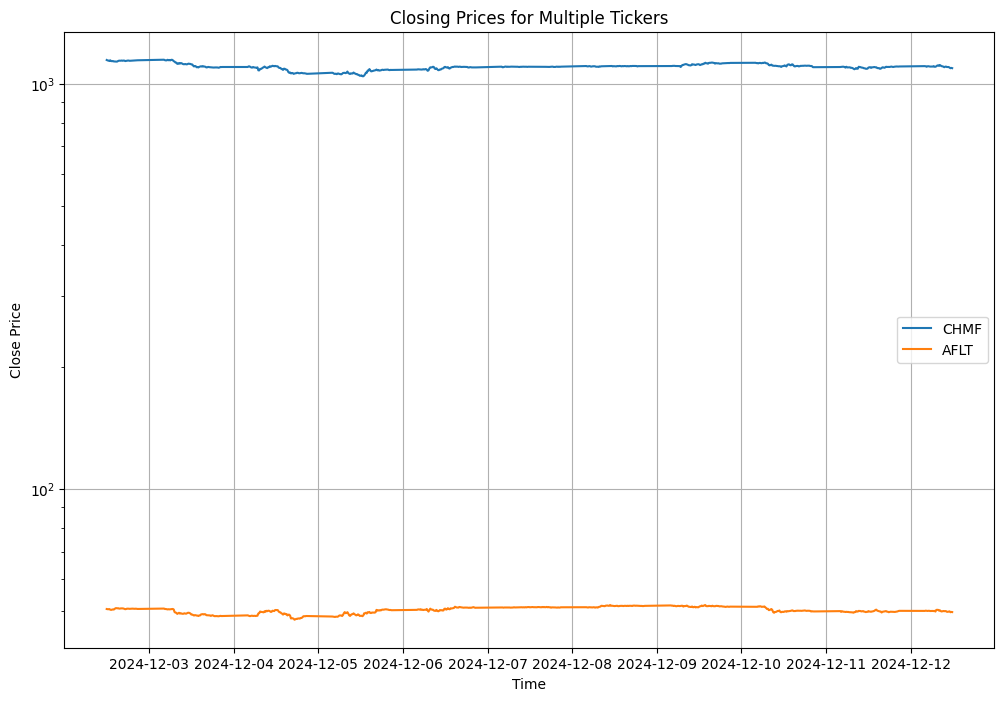

In [29]:
import matplotlib.pyplot as plt

def plot_multi_ticker_close(df, tickers):
    plt.figure(figsize=(12, 8))
    for ticker in tickers:
        ticker_data = df[df['tic'] == ticker]
        plt.plot(ticker_data['date'], ticker_data['close'], label=ticker)

    
    # Set y-axis to logarithmic
    plt.yscale('log')
    plt.title('Closing Prices for Multiple Tickers')

    plt.xlabel('Time')
    plt.ylabel('Close Price')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
plot_multi_ticker_close(df, ['CHMF', 'AFLT'])


In [ ]:
import requests
import pandas as pd
import logging
import time

from datetime import timedelta
from bs4 import BeautifulSoup
from tinkoff.invest.sandbox.client import SandboxClient as Client
from tinkoff.invest import SecurityTradingStatus
from tinkoff.invest.services import InstrumentsService
from tinkoff.invest.utils import quotation_to_decimal

from tdata import get_figis, extract_tickers

def fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN):
    """
    Fetch OHLCV data for multiple FIGIs with progress logging.
    """
    # List to store rows of data
    data_rows = []

    # Define the maximum period per request for each interval
    max_periods = {
        "CANDLE_INTERVAL_1_MIN": timedelta(days=1),
        "CANDLE_INTERVAL_5_MIN": timedelta(days=7),
        "CANDLE_INTERVAL_15_MIN": timedelta(days=21),
        "CANDLE_INTERVAL_HOUR": timedelta(days=90),
        "CANDLE_INTERVAL_2_HOUR": timedelta(days=90),
        "CANDLE_INTERVAL_4_HOUR": timedelta(days=90),
        "CANDLE_INTERVAL_DAY": timedelta(days=365),
        "CANDLE_INTERVAL_WEEK": timedelta(days=365 * 5),
    }

    # Get the maximum allowable period for the given interval
    max_duration = max_periods.get(interval, timedelta(days=1))  # Default to 1 day if interval is unknown

    total_figis = len(ticker_figis)  # Total number of FIGIs to process
    total_data_points = 0  # Total data points fetched

    with Client(TOKEN) as client:
        for figi_index, (ticker, figi) in enumerate(ticker_figis, start=1):  # Enumerate to track progress
            print(f"Processing {ticker} ({figi}) [{figi_index}/{total_figis}]...")
            current_start = start_date
            figi_data_points = 0  # Data points fetched for this FIGI

            while current_start < end_date:
                # Calculate the end of the current chunk
                current_end = min(current_start + max_duration, end_date)
                try:
                    # Fetch candles for the current chunk
                    candles = client.market_data.get_candles(
                        figi=figi,
                        from_=current_start,
                        to=current_end,
                        interval=interval,
                    )

                    # Append each candle as a row with ticker and figi
                    for candle in candles.candles:
                        row = {
                            "figi": figi,
                            "date": candle.time,
                            "open": candle.open.units + candle.open.nano / 1e9,
                            "high": candle.high.units + candle.high.nano / 1e9,
                            "low": candle.low.units + candle.low.nano / 1e9,
                            "close": candle.close.units + candle.close.nano / 1e9,
                            "volume": candle.volume,
                            "tic": ticker,
                            "day": candle.time.weekday(),
                        }
                        data_rows.append(row)
                        figi_data_points += 1

                    # Move to the next time chunk only if the current batch is successful
                    current_start = current_end

                except Exception as e:
                    print(f"Failed to fetch data for FIGI {figi} (Ticker: {ticker}): {e}")

                    # Check if the error is RESOURCE_EXHAUSTED
                    if "RESOURCE_EXHAUSTED" in str(e):
                        # Extract reset time from the metadata if available
                        metadata = getattr(e.args[-1], 'ratelimit_reset', None)
                        reset_time = int(metadata) if metadata else 60  # Default to 60 seconds if not available
                        print(f"Rate limit exceeded. Fetched {figi_data_points} rows so far for {ticker}.")
                        print(f"Sleeping for {reset_time} seconds...")
                        time.sleep(reset_time)
                    else:
                        # Log and continue for other errors
                        # Skip this batch as it's not recoverable
                        break

            # Log progress for the current FIGI
            print(f"Completed {ticker} ({figi}). Total rows fetched for this FIGI: {figi_data_points}.")
            total_data_points += figi_data_points

    # Convert the list of rows into a DataFrame
    df = pd.DataFrame(data_rows)

    # Final log output
    print(f"All rows fetched: {total_data_points} rows in total.")
    return df


TOKEN = 't.DBEaAVcPDDWGkElTk898UNX9yH_ADegVdZgaWKC4a-Ktgz1sbbd-G_9yQf0PeiVEeKuoMWEpUuMT-TNCQzaw1g'

if __name__ == "__main__":
    # Set date range for historical data
    end_date = pd.Timestamp("2024-12-31T12:00:00Z")
    start_date = end_date - pd.Timedelta(days=10)
    interval = CandleInterval.CANDLE_INTERVAL_1_MIN
    ticker_figis = get_figis(extract_tickers(), TOKEN)
    test_df = fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN)


In [ ]:
!pytest test_tdata.py

============================= test session starts ==============================
platform linux -- Python 3.10.12, pytest-8.3.4, pluggy-1.5.0
rootdir: /src
configfile: setup.cfg
plugins: anyio-4.7.0
collected 9 items                                                              

test_tdata.py ........